In [38]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

In [39]:
gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss <- gss |> drop_na(realinc, educ)

gss |> glimpse()

Rows: 67,731
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


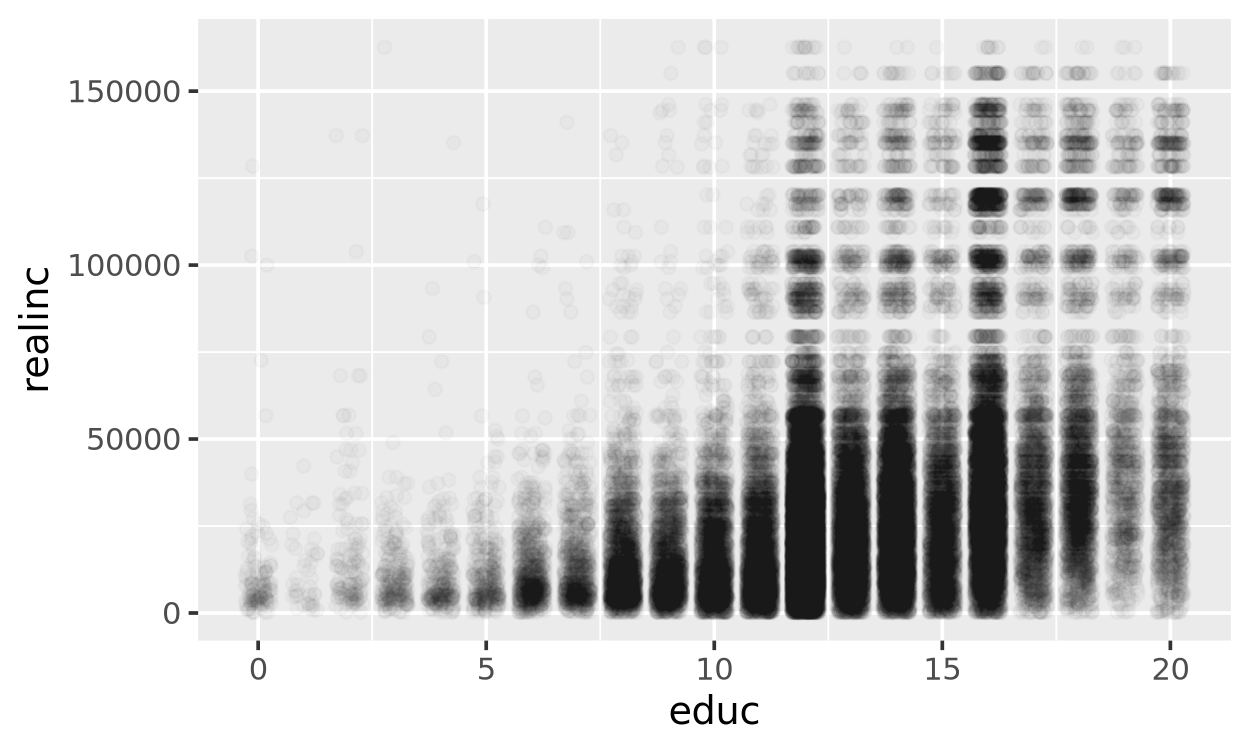

In [40]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_point(
        alpha = 0.02,
        position = position_jitter(width = 0.3, height = 0, seed = 512)
    )

## Step 1: Random parameter combinations

We model `realinc` as a straight line in `educ`:

$$\text{realinc} = \text{intercept} + \text{slope} \times \text{educ}$$

Each row below is one candidate model, defined by a random `intercept` and `slope`.
From the data, `educ` runs 0–20 and `realinc` runs ~180–162,000, so we sample:

- `intercept`: -50,000 to 50,000
- `slope`: -5,000 to 10,000 (income change per extra year of education)

We'll score each row later and keep the best one.

In [41]:
set.seed(512)

n_combo <- 1000

params <- tibble(
    id        = 1:n_combo,
    intercept = runif(n_combo, min = -50000, max = 50000),
    slope     = runif(n_combo, min = 0,  max = 5000)
)

params |> glimpse()

Rows: 1,000
Columns: 3
$ id        <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> -11466.7282, -36613.3343, -4324.0748, 43243.4121, 14374.8909…
$ slope     <dbl> 2933.03293, 647.21229, 4627.90680, 878.81020, 3667.28613, 34…


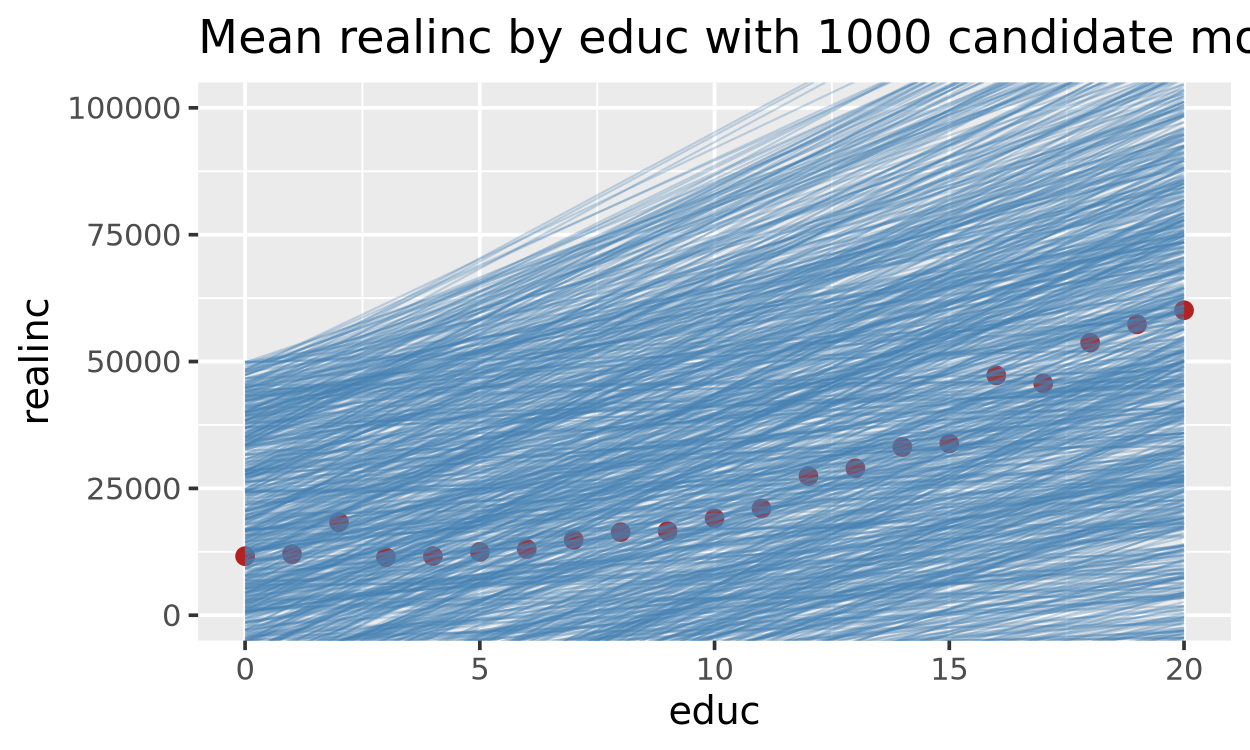

In [42]:
gss_means <- gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc), .groups = "drop")

model_lines <- params |>
    crossing(educ = c(0, 20)) |>
    mutate(realinc = intercept + slope * educ)

ggplot() +
    geom_point(
        data = gss_means, aes(x = educ, y = realinc),
        color = "firebrick", size = 2
    ) +
    geom_line(
        data = model_lines, aes(x = educ, y = realinc, group = id),
        alpha = 0.3, color = "steelblue", linewidth = 0.3
    ) +
    coord_cartesian(ylim = c(0, 100000)) +
    labs(title = "Mean realinc by educ with 1000 candidate models")

Steps for creating a model:

1. Pick the model form:

   $$\text{realinc} = \beta_0 + \beta_1 \cdot \text{educ}$$

   where $\beta_0$ is the intercept and $\beta_1$ is the slope.

2. Design a way to evaluate different model parameters.
3. Optimize our parameter values.

In [43]:
calc_rmse <- function(intercept, slope, data = gss) {
    predicted <- intercept + slope * data$educ
    sqrt(mean((data$realinc - predicted)^2))
}

In [44]:
params <- params |>
    mutate(rmse = map2_dbl(intercept, slope, calc_rmse))

params |> glimpse()

Rows: 1,000
Columns: 4
$ id        <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> -11466.7282, -36613.3343, -4324.0748, 43243.4121, 14374.8909…
$ slope     <dbl> 2933.03293, 647.21229, 4627.90680, 878.81020, 3667.28613, 34…
$ rmse      <dbl> 28891.29, 67570.73, 37243.29, 36989.61, 41277.59, 33053.84, …


In [45]:
fit <- lm(realinc ~ educ, data = gss)

fit |>
    augment() |>
    select(realinc, educ, .fitted, .resid) |>
    glimpse()

Rows: 67,731
Columns: 4
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ .fitted <dbl> 42743.459, 21287.658, 28439.592, 46319.426, 28439.592, 35591.5…
$ .resid  <dbl> -23792.4588, 3078.3418, -4073.5917, -15861.4256, 22323.4083, 8…


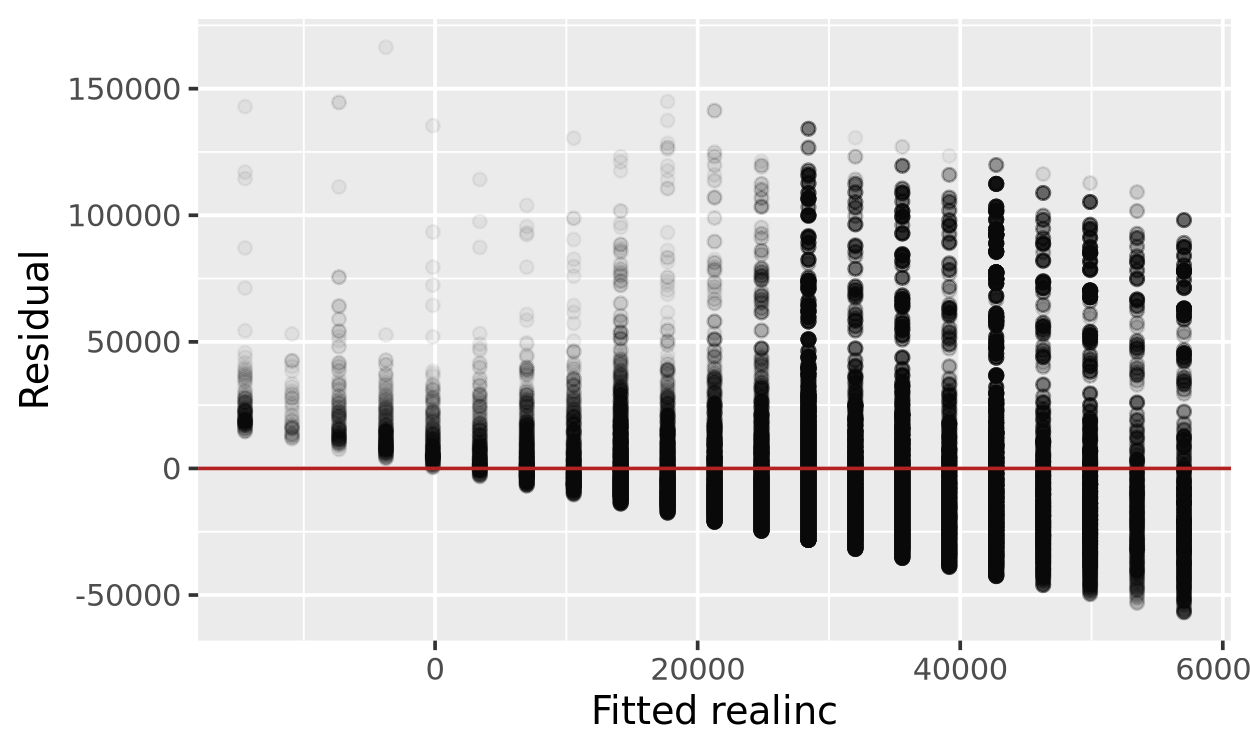

In [46]:
fit |>
    augment() |>
    ggplot(aes(x = .fitted, y = .resid)) +
    geom_point(alpha = 0.05) +
    geom_hline(yintercept = 0, color = "firebrick") +
    labs(x = "Fitted realinc", y = "Residual")

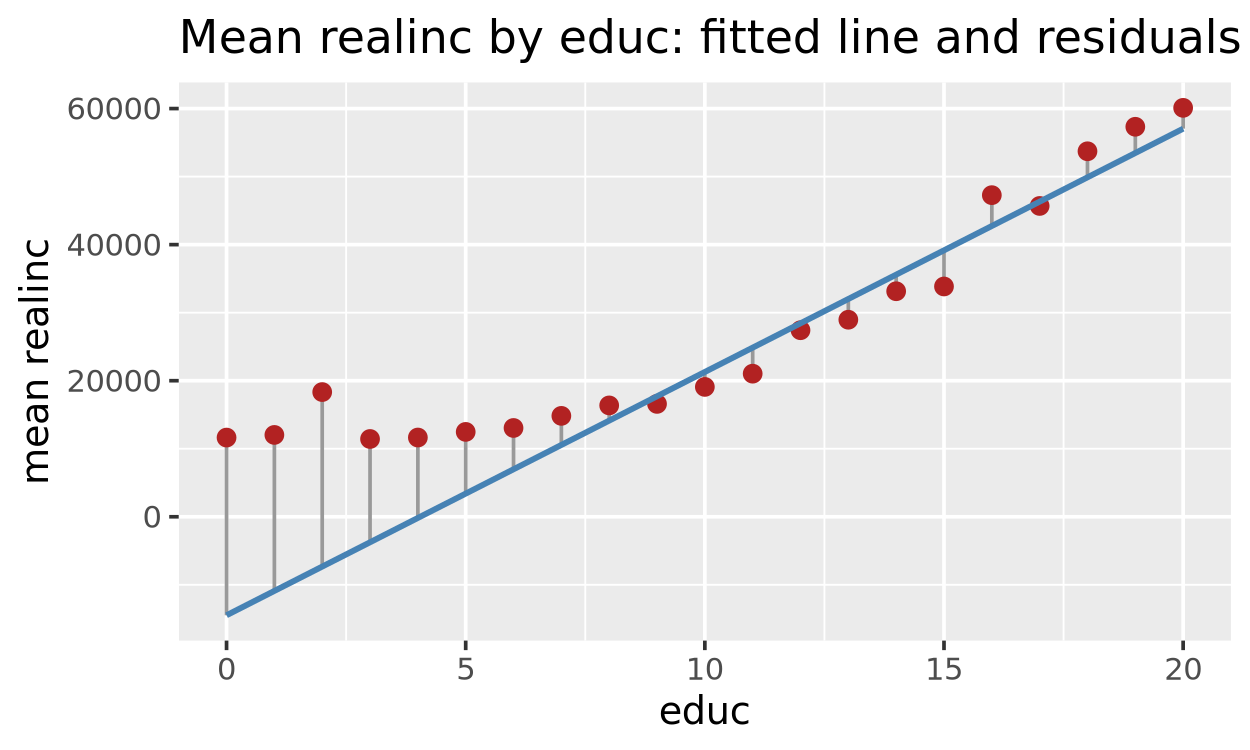

In [47]:
gss_means |>
    mutate(
        .fitted = predict(fit, newdata = gss_means),
        .resid  = realinc - .fitted
    ) |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_segment(aes(xend = educ, yend = .fitted), color = "grey60") +
    geom_point(color = "firebrick", size = 2) +
    geom_line(aes(y = .fitted), color = "steelblue", linewidth = 0.8) +
    labs(
        x = "educ", y = "mean realinc",
        title = "Mean realinc by educ: fitted line and residuals"
    )

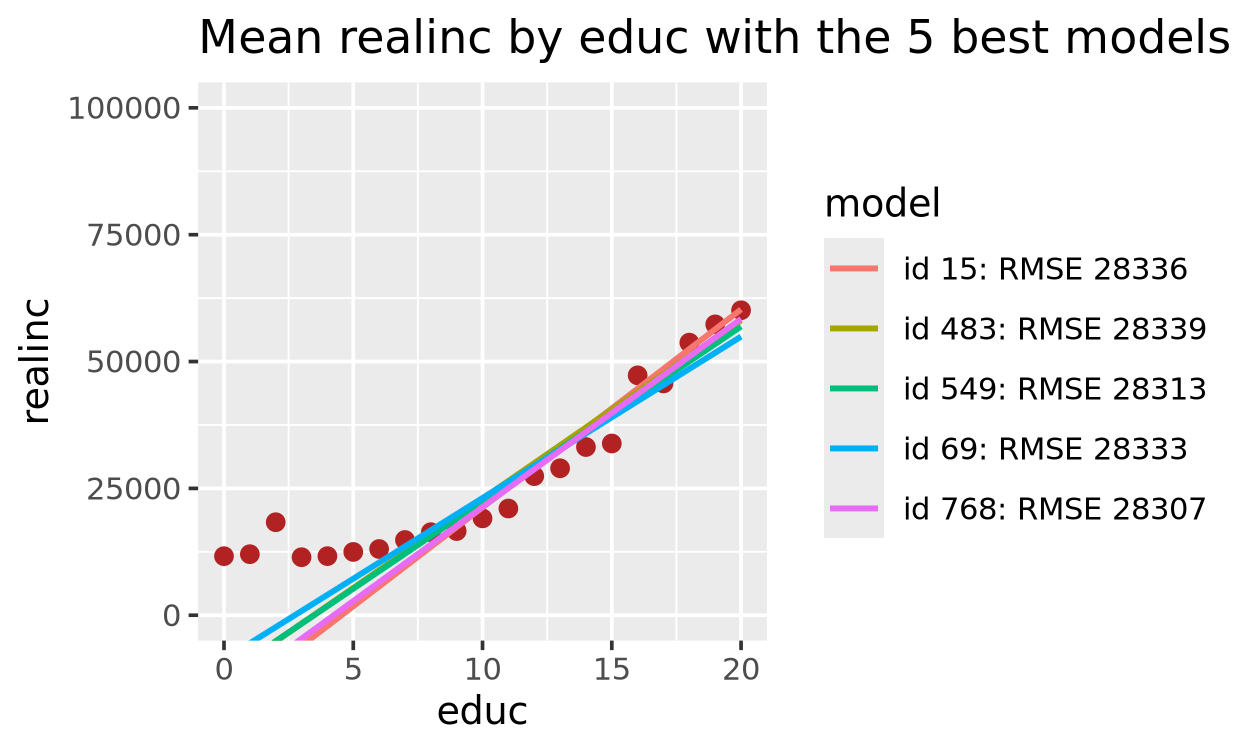

In [48]:
top5 <- params |>
    slice_min(rmse, n = 5)

model_lines_top5 <- top5 |>
    crossing(educ = c(0, 20)) |>
    mutate(
        realinc = intercept + slope * educ,
        model   = factor(sprintf("id %d: RMSE %.0f", id, rmse))
    )

ggplot() +
    geom_point(
        data = gss_means, aes(x = educ, y = realinc),
        color = "firebrick", size = 2
    ) +
    geom_line(
        data = model_lines_top5,
        aes(x = educ, y = realinc, color = model),
        linewidth = 0.8
    ) +
    coord_cartesian(ylim = c(0, 100000)) +
    labs(
        title = "Mean realinc by educ with the 5 best models by RMSE",
        color = "model"
    )